# STAT 390 — Presentation 3
## Data Engineer Choice 2: Patch Feature Analysis

**Research objective:** Characterize the pathology patches associated with each eligible case and identify cases with unusual patch characteristics.

### 1. Stain Classification and Filename Standardization

The initial feature-extraction script produced `patch_features_all.csv`, containing measurements for 85,413 PNG images from 99 eligible cases. All images were read successfully, but 1,151 filenames were flagged because their stain names did not match the exact naming patterns used by the initial parser.

A subsequent audit identified two variations:

- `h&e-labels`: 1,048 patches
- `sox10.`: 103 patches

Inspection of `data_utils.py` (lines 239–248) showed that the original pipeline uses substring matching to identify stains. Therefore, the corrected table will classify these filenames as H&E and SOX10, respectively.

The transformation will preserve the original stain classifications and add a flag for filenames containing `h&e-labels`. Although the pipeline recognizes these files as H&E, their visual contents have not yet been independently verified.

The original CSV will remain unchanged. The corrected output will be saved as `patch_features_corrected.csv`.


In [ ]:
import pandas as pd
from pathlib import Path

# Load the original patch-level feature table.
original = pd.read_csv("patch_features_all.csv")

# Preserve the original measurements.
corrected = original.copy()

# Reproduce the stain-classification logic in data_utils.py.
def identify_stain(filename):
    filename_lower = filename.lower()

    if "h&e" in filename_lower or "_he_" in filename_lower:
        return "h&e"
    elif "melan" in filename_lower:
        return "melan"
    elif "sox10" in filename_lower:
        return "sox10"

    return "unrecognized"


# Preserve the initial stain classification.
corrected["original_stain"] = corrected["stain"]

# Apply the project's stain-classification rules.
corrected["stain"] = corrected["filename"].apply(identify_stain)

# Flag filenames that might be annotation-related.
corrected["annotation_name_flag"] = corrected["filename"].str.contains(
    "h&e-labels",
    case=False,
    regex=False
)

# Check the output path before saving.
output_path = Path("patch_features_corrected.csv")

if output_path.exists():
    raise FileExistsError(
        f"{output_path} already exists. "
        "Review the existing file before replacing it."
    )

# Save the corrected table without overwriting the original.
with output_path.open("x", newline="") as output_file:
    corrected.to_csv(output_file, index=False)

print("Original patch records:", len(original))
print("Corrected patch records:", len(corrected))
print("Output file:", output_path)

print("\nStain classifications changed:")
print(
    (corrected["stain"] != corrected["original_stain"]).sum()
)

print("\nCorrected stain counts:")
print(corrected["stain"].value_counts())

print("\nPotential annotation-related filenames:")
print(corrected["annotation_name_flag"].sum())


In [1]:
# VALIDATION OF CORRECTED PATCH FEATURES

import pandas as pd

original = pd.read_csv("patch_features_all.csv")
corrected = pd.read_csv("patch_features_corrected.csv")

# 1. Verify no patch records were lost.
assert len(original) == len(corrected) == 85413, (
    "Unexpected number of patch records"
)

# 2. Verify all 99 eligible cases are represented.
assert corrected["case_id"].nunique() == 99, (
    "Unexpected number of cases"
)

# 3. Verify the same filenames appear in both tables.
assert set(original["filename"]) == set(corrected["filename"]), (
    "The filenames differ between the two tables"
)

# 4. Verify the number of corrected stain classifications.
changed = (
    corrected["stain"] != corrected["original_stain"]
).sum()

assert changed == 1151, (
    f"Expected 1151 corrections, found {changed}"
)

# 5. Verify every stain is recognized.
valid_stains = {"h&e", "melan", "sox10"}

assert set(corrected["stain"]) <= valid_stains, (
    "Unrecognized stains remain"
)

# 6. Verify image dimensions are present.
assert corrected[
    ["width_px", "height_px", "area_px2"]
].notna().all().all(), (
    "Missing image measurements found"
)

# 7. Verify patch areas were preserved.
assert (
    original["area_px2"].equals(corrected["area_px2"])
), "Patch areas changed unexpectedly"

# 8. Verify potential annotation filenames are tracked.
annotation_count = corrected["annotation_name_flag"].sum()

assert annotation_count == 1048, (
    f"Expected 1048 annotation-name flags, found {annotation_count}"
)

print("ALL VALIDATION CHECKS PASSED")
print("=" * 50)
print("Patch records:", len(corrected))
print("Eligible cases:", corrected["case_id"].nunique())
print("Stain classifications corrected:", changed)
print("Potential annotation filenames:", annotation_count)

print("\nCorrected stain distribution:")
print(corrected["stain"].value_counts())


ALL VALIDATION CHECKS PASSED
Patch records: 85413
Eligible cases: 99
Stain classifications corrected: 1151
Potential annotation filenames: 1048

Corrected stain distribution:
stain
h&e      42180
melan    23469
sox10    19764
Name: count, dtype: int64


## 2. Case-Level Patch Feature Analysis

### Objective

Summarize the characteristics of the 85,413 eligible PNG patches into a case-level feature table containing one row for each of the 99 eligible cases.

### Methods

For each case, we calculate:

1. Total number of PNG patches.
2. Number of distinct slice identifiers.
3. Average number of patches per slice.
4. Median patch area in pixels squared.
5. Patch-area interquartile range (75th percentile minus 25th percentile).
6. Proportion of patches belonging to H&E, Melan-A, and SOX10.
7. Proportion of patches smaller than 128 × 128 pixels.
8. Number of filenames containing the potentially annotation-related `h&e-labels` pattern.

Patch area is calculated as width multiplied by height.

Distinct slices are identified using the normalized `slice_id` field, independently of stain. The number of stain-slice combinations is also recorded separately.

Stain proportions are calculated using the classifications established in the previous section.

These features describe the available PNG collection, not necessarily the subset of embeddings successfully loaded by UNI2.

The output will be saved as `case_patch_features.csv`.


In [ ]:
import pandas as pd
from pathlib import Path

# Load the corrected patch-level dataset.
df = pd.read_csv("patch_features_corrected.csv")

# Verify expected input structure.
assert len(df) == 85413
assert df["case_id"].nunique() == 99
assert df["slice_id"].notna().all()
assert df["area_px2"].notna().all()
assert df["stain"].isin(["h&e", "melan", "sox10"]).all()

# Ensure each case has a consistent diagnosis.
assert df.groupby("case_id")["grade"].nunique().eq(1).all()

# Convert patch area to numeric values.
df["area_px2"] = pd.to_numeric(df["area_px2"])

# Identify patches smaller than 128 x 128 pixels.
# Both dimensions must be below 128.
df["small_patch"] = (
    (df["width_px"] < 128) &
    (df["height_px"] < 128)
)

# Count patches for each stain.
df["is_he"] = df["stain"].eq("h&e")
df["is_melan"] = df["stain"].eq("melan")
df["is_sox10"] = df["stain"].eq("sox10")

# Build one row per case.
case_features = df.groupby("case_id").agg(
    grade=("grade", "first"),
    total_patches=("filename", "count"),
    num_slices=("slice_id", "nunique"),
    median_patch_area=("area_px2", "median"),
    q1_patch_area=("area_px2", lambda x: x.quantile(0.25)),
    q3_patch_area=("area_px2", lambda x: x.quantile(0.75)),
    he_share=("is_he", "mean"),
    melan_share=("is_melan", "mean"),
    sox10_share=("is_sox10", "mean"),
    small_patch_share=("small_patch", "mean"),
    annotation_flag_count=("annotation_name_flag", "sum")
).reset_index()

# Calculate interquartile range.
case_features["patch_area_IQR"] = (
    case_features["q3_patch_area"] -
    case_features["q1_patch_area"]
)

# Calculate patches per distinct slice.
case_features["patches_per_slice"] = (
    case_features["total_patches"] /
    case_features["num_slices"]
)

# Count distinct stain-slice combinations separately.
stain_slice_counts = (
    df.groupby("case_id")
      .apply(
          lambda g: g[
              ["stain", "slice_id"]
          ].drop_duplicates().shape[0],
          include_groups=False
      )
      .rename("num_stain_slice_combinations")
      .reset_index()
)

case_features = case_features.merge(
    stain_slice_counts,
    on="case_id",
    how="left",
    validate="one_to_one"
)

# Organize the columns.
columns = [
    "case_id",
    "grade",
    "total_patches",
    "num_slices",
    "num_stain_slice_combinations",
    "patches_per_slice",
    "median_patch_area",
    "patch_area_IQR",
    "he_share",
    "melan_share",
    "sox10_share",
    "small_patch_share",
    "annotation_flag_count"
]

case_features = case_features[columns]

# Save the table without overwriting an existing file.
output_path = Path("case_patch_features.csv")

with output_path.open("x", newline="") as output_file:
    case_features.to_csv(output_file, index=False)

print("CASE-LEVEL FEATURE EXTRACTION COMPLETE")
print("=" * 55)

print("Total cases:", len(case_features))
print("Total patches:", case_features["total_patches"].sum())
print("Output:", output_path)

print("\nFirst five cases:")
print(case_features.head().to_string(index=False))


In [2]:
# VALIDATION OF CASE-LEVEL PATCH FEATURES

import pandas as pd
import numpy as np

# Load the patch-level and case-level tables.
patches = pd.read_csv("patch_features_corrected.csv")
cases = pd.read_csv("case_patch_features.csv")

print("CASE-LEVEL FEATURE VALIDATION")
print("=" * 55)

# 1. Verify exactly 99 cases.
assert len(cases) == 99, (
    f"Expected 99 cases, found {len(cases)}"
)

# 2. Verify each case ID appears once.
assert cases["case_id"].is_unique, (
    "Duplicate case IDs found"
)

# 3. Verify all patch records are represented.
assert cases["total_patches"].sum() == len(patches) == 85413, (
    "Patch totals do not match"
)

# 4. Verify every case has a positive slice count.
assert (cases["num_slices"] > 0).all(), (
    "A case has zero slices"
)

# 5. Verify stain proportions sum to 1.
stain_columns = [
    "he_share",
    "melan_share",
    "sox10_share"
]

stain_totals = cases[stain_columns].sum(axis=1)

assert np.allclose(stain_totals, 1.0), (
    "Stain proportions do not sum to 1"
)

# 6. Verify patch areas are positive.
assert (cases["median_patch_area"] > 0).all(), (
    "Invalid median patch area"
)

# 7. Verify patch-area IQRs are nonnegative.
assert (cases["patch_area_IQR"] >= 0).all(), (
    "Negative patch-area IQR found"
)

# 8. Verify small-patch shares are between 0 and 1.
assert cases["small_patch_share"].between(0, 1).all(), (
    "Invalid small-patch proportions"
)

# 9. Verify annotation flags were preserved.
assert cases["annotation_flag_count"].sum() == 1048, (
    "Annotation filename counts do not match"
)

# 10. Independently verify patches per slice.
expected_per_slice = (
    cases["total_patches"] / cases["num_slices"]
)

assert np.allclose(
    cases["patches_per_slice"],
    expected_per_slice
), "Incorrect patches-per-slice calculations"

# 11. Verify that case IDs match the patch-level table.
assert set(cases["case_id"]) == set(patches["case_id"]), (
    "Case IDs differ between tables"
)

print("ALL 11 VALIDATION CHECKS PASSED")
print("=" * 55)

print("Total cases:", len(cases))
print("Total patches:", cases["total_patches"].sum())
print("Unique cases:", cases["case_id"].nunique())
print("Annotation-related filenames:",
      cases["annotation_flag_count"].sum())

print("\nOverall patch-size statistics:")
print(
    cases[
        ["median_patch_area",
         "patch_area_IQR",
         "small_patch_share"]
    ].describe().round(2)
)


CASE-LEVEL FEATURE VALIDATION
ALL 11 VALIDATION CHECKS PASSED
Total cases: 99
Total patches: 85413
Unique cases: 99
Annotation-related filenames: 1048

Overall patch-size statistics:
       median_patch_area  patch_area_IQR  small_patch_share
count              99.00           99.00              99.00
mean           148429.36       213921.57               0.26
std            596650.99       688144.41               0.20
min              2652.00         2772.50               0.00
25%             23028.00        25649.50               0.10
50%             38220.00        41231.00               0.22
75%             61818.00        80892.00               0.37
max           4205575.00      4190393.25               0.98


## 3. Identifying Unusual Cases

### Objective

Identify cases whose patch characteristics differ substantially from the rest of the 99-case dataset.

### Statistical method

For each numerical feature, we apply Tukey's 1.5 × IQR rule.

The lower and upper thresholds are:

- Lower threshold = Q1 − 1.5 × IQR
- Upper threshold = Q3 + 1.5 × IQR

A case is flagged when its feature value falls outside these thresholds.

The following features are examined:

1. Median patch area.
2. Patch-area IQR.
3. Proportion of small patches.
4. H&E proportion.
5. Melan-A proportion.
6. SOX10 proportion.
7. Average patches per slice.

### Additional data-quality flags

Cases with no available patches from one of the three stains are flagged separately, even if their stain proportions do not exceed the statistical thresholds.

Cases containing filenames with `h&e-labels` are also identified separately because their image contents have not yet been independently verified.

### Interpretation

These flags identify unusual characteristics of the available PNG patches. They do not establish that a case was misclassified or that a feature caused classification difficulty.

The output will be saved as `unusual_cases.csv`.


In [ ]:
import pandas as pd
from pathlib import Path

# Load the validated case-level feature table.
df = pd.read_csv("case_patch_features.csv")

assert len(df) == 99
assert df["case_id"].is_unique

# Numerical features to examine.
features = [
    "median_patch_area",
    "patch_area_IQR",
    "small_patch_share",
    "he_share",
    "melan_share",
    "sox10_share",
    "patches_per_slice"
]

records = []

# Apply the 1.5 x IQR rule.
for feature in features:

    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    for _, row in df.iterrows():

        value = row[feature]

        if value < lower:
            direction = "Below lower threshold"

        elif value > upper:
            direction = "Above upper threshold"

        else:
            continue

        records.append({
            "case_id": int(row["case_id"]),
            "grade": row["grade"],
            "flag_type": "Statistical outlier",
            "feature": feature,
            "value": value,
            "lower_threshold": lower,
            "upper_threshold": upper,
            "reason": direction
        })

# Explicitly flag missing stains.
stain_columns = {
    "h&e": "he_share",
    "melan": "melan_share",
    "sox10": "sox10_share"
}

for _, row in df.iterrows():

    for stain, column in stain_columns.items():

        if row[column] == 0:

            records.append({
                "case_id": int(row["case_id"]),
                "grade": row["grade"],
                "flag_type": "Missing stain",
                "feature": column,
                "value": 0,
                "lower_threshold": "",
                "upper_threshold": "",
                "reason": f"No {stain} PNG patches"
            })

# Separately flag annotation-related filename patterns.
for _, row in df.iterrows():

    if row["annotation_flag_count"] > 0:

        records.append({
            "case_id": int(row["case_id"]),
            "grade": row["grade"],
            "flag_type": "Filename review",
            "feature": "annotation_flag_count",
            "value": int(row["annotation_flag_count"]),
            "lower_threshold": "",
            "upper_threshold": "",
            "reason": "Contains h&e-labels filenames"
        })

# Create the unusual-case table.
unusual = pd.DataFrame(records)

if unusual.empty:
    print("No unusual cases were identified.")

else:
    unusual = unusual.sort_values(
        ["case_id", "flag_type", "feature"]
    ).reset_index(drop=True)

# Save without overwriting existing results.
output_path = Path("unusual_cases.csv")

with output_path.open("x", newline="") as output_file:
    unusual.to_csv(output_file, index=False)

print("UNUSUAL-CASE ANALYSIS COMPLETE")
print("=" * 60)

print("Total cases examined:", len(df))

print("Total flags:", len(unusual))

print("Distinct flagged cases:",
      unusual["case_id"].nunique() if len(unusual) else 0)

print("\nFlags by type:")
print(unusual["flag_type"].value_counts())

print("\nCases with the most flags:")

if len(unusual):
    print(
        unusual.groupby("case_id")
        .size()
        .sort_values(ascending=False)
        .head(15)
        .to_string()
    )

print("\nOutput:", output_path)


In [3]:
# VALIDATION OF UNUSUAL CASE FLAGS

import pandas as pd

cases = pd.read_csv("case_patch_features.csv")
flags = pd.read_csv("unusual_cases.csv")

print("UNUSUAL CASE VALIDATION")
print("=" * 55)

# Verify the number of flags and unique cases.
assert len(flags) == 39
assert flags["case_id"].nunique() == 23

# Verify every flagged case exists in our case table.
assert set(flags["case_id"]).issubset(set(cases["case_id"]))

# Verify flag categories and their counts.
expected_types = {
    "Statistical outlier",
    "Missing stain",
    "Filename review"
}

assert set(flags["flag_type"]) == expected_types

counts = flags["flag_type"].value_counts()

assert counts["Statistical outlier"] == 31
assert counts["Missing stain"] == 4
assert counts["Filename review"] == 4

# Verify required information is complete.
required_columns = [
    "case_id", "grade", "flag_type", "feature", "reason"
]

assert flags[required_columns].notna().all().all()

# Verify no duplicate flags.
assert not flags.duplicated(
    subset=["case_id", "flag_type", "feature"]
).any()

# Verify missing-stain flags against the case-level table.
missing = flags[flags["flag_type"] == "Missing stain"]

for _, row in missing.iterrows():
    case_row = cases.loc[cases["case_id"] == row["case_id"]]

    assert len(case_row) == 1
    assert case_row.iloc[0][row["feature"]] == 0

print("ALL 8 VALIDATION CHECKS PASSED")
print("=" * 55)
print("Total flags:", len(flags))
print("Distinct flagged cases:", flags["case_id"].nunique())
print("Flag types:", counts.to_dict())
print("Missing-stain records verified:", len(missing))


UNUSUAL CASE VALIDATION
ALL 8 VALIDATION CHECKS PASSED
Total flags: 39
Distinct flagged cases: 23
Flag types: {'Statistical outlier': 31, 'Missing stain': 4, 'Filename review': 4}
Missing-stain records verified: 4


## Visualization 1: Distribution of Case-Level Patch Sizes

This histogram displays the median patch area for each of the 99 eligible cases.

The horizontal axis uses a logarithmic scale because patch areas vary substantially.

Cases 62 and 91 are highlighted to illustrate exceptionally small and large median patch sizes.

These differences describe the input data. They do not, by themselves, establish whether a case is difficult for the model to classify.


VISUALIZATION CREATED
Cases represented: 99
Case 62 median area: 2652.0
Case 91 median area: 4205575.0


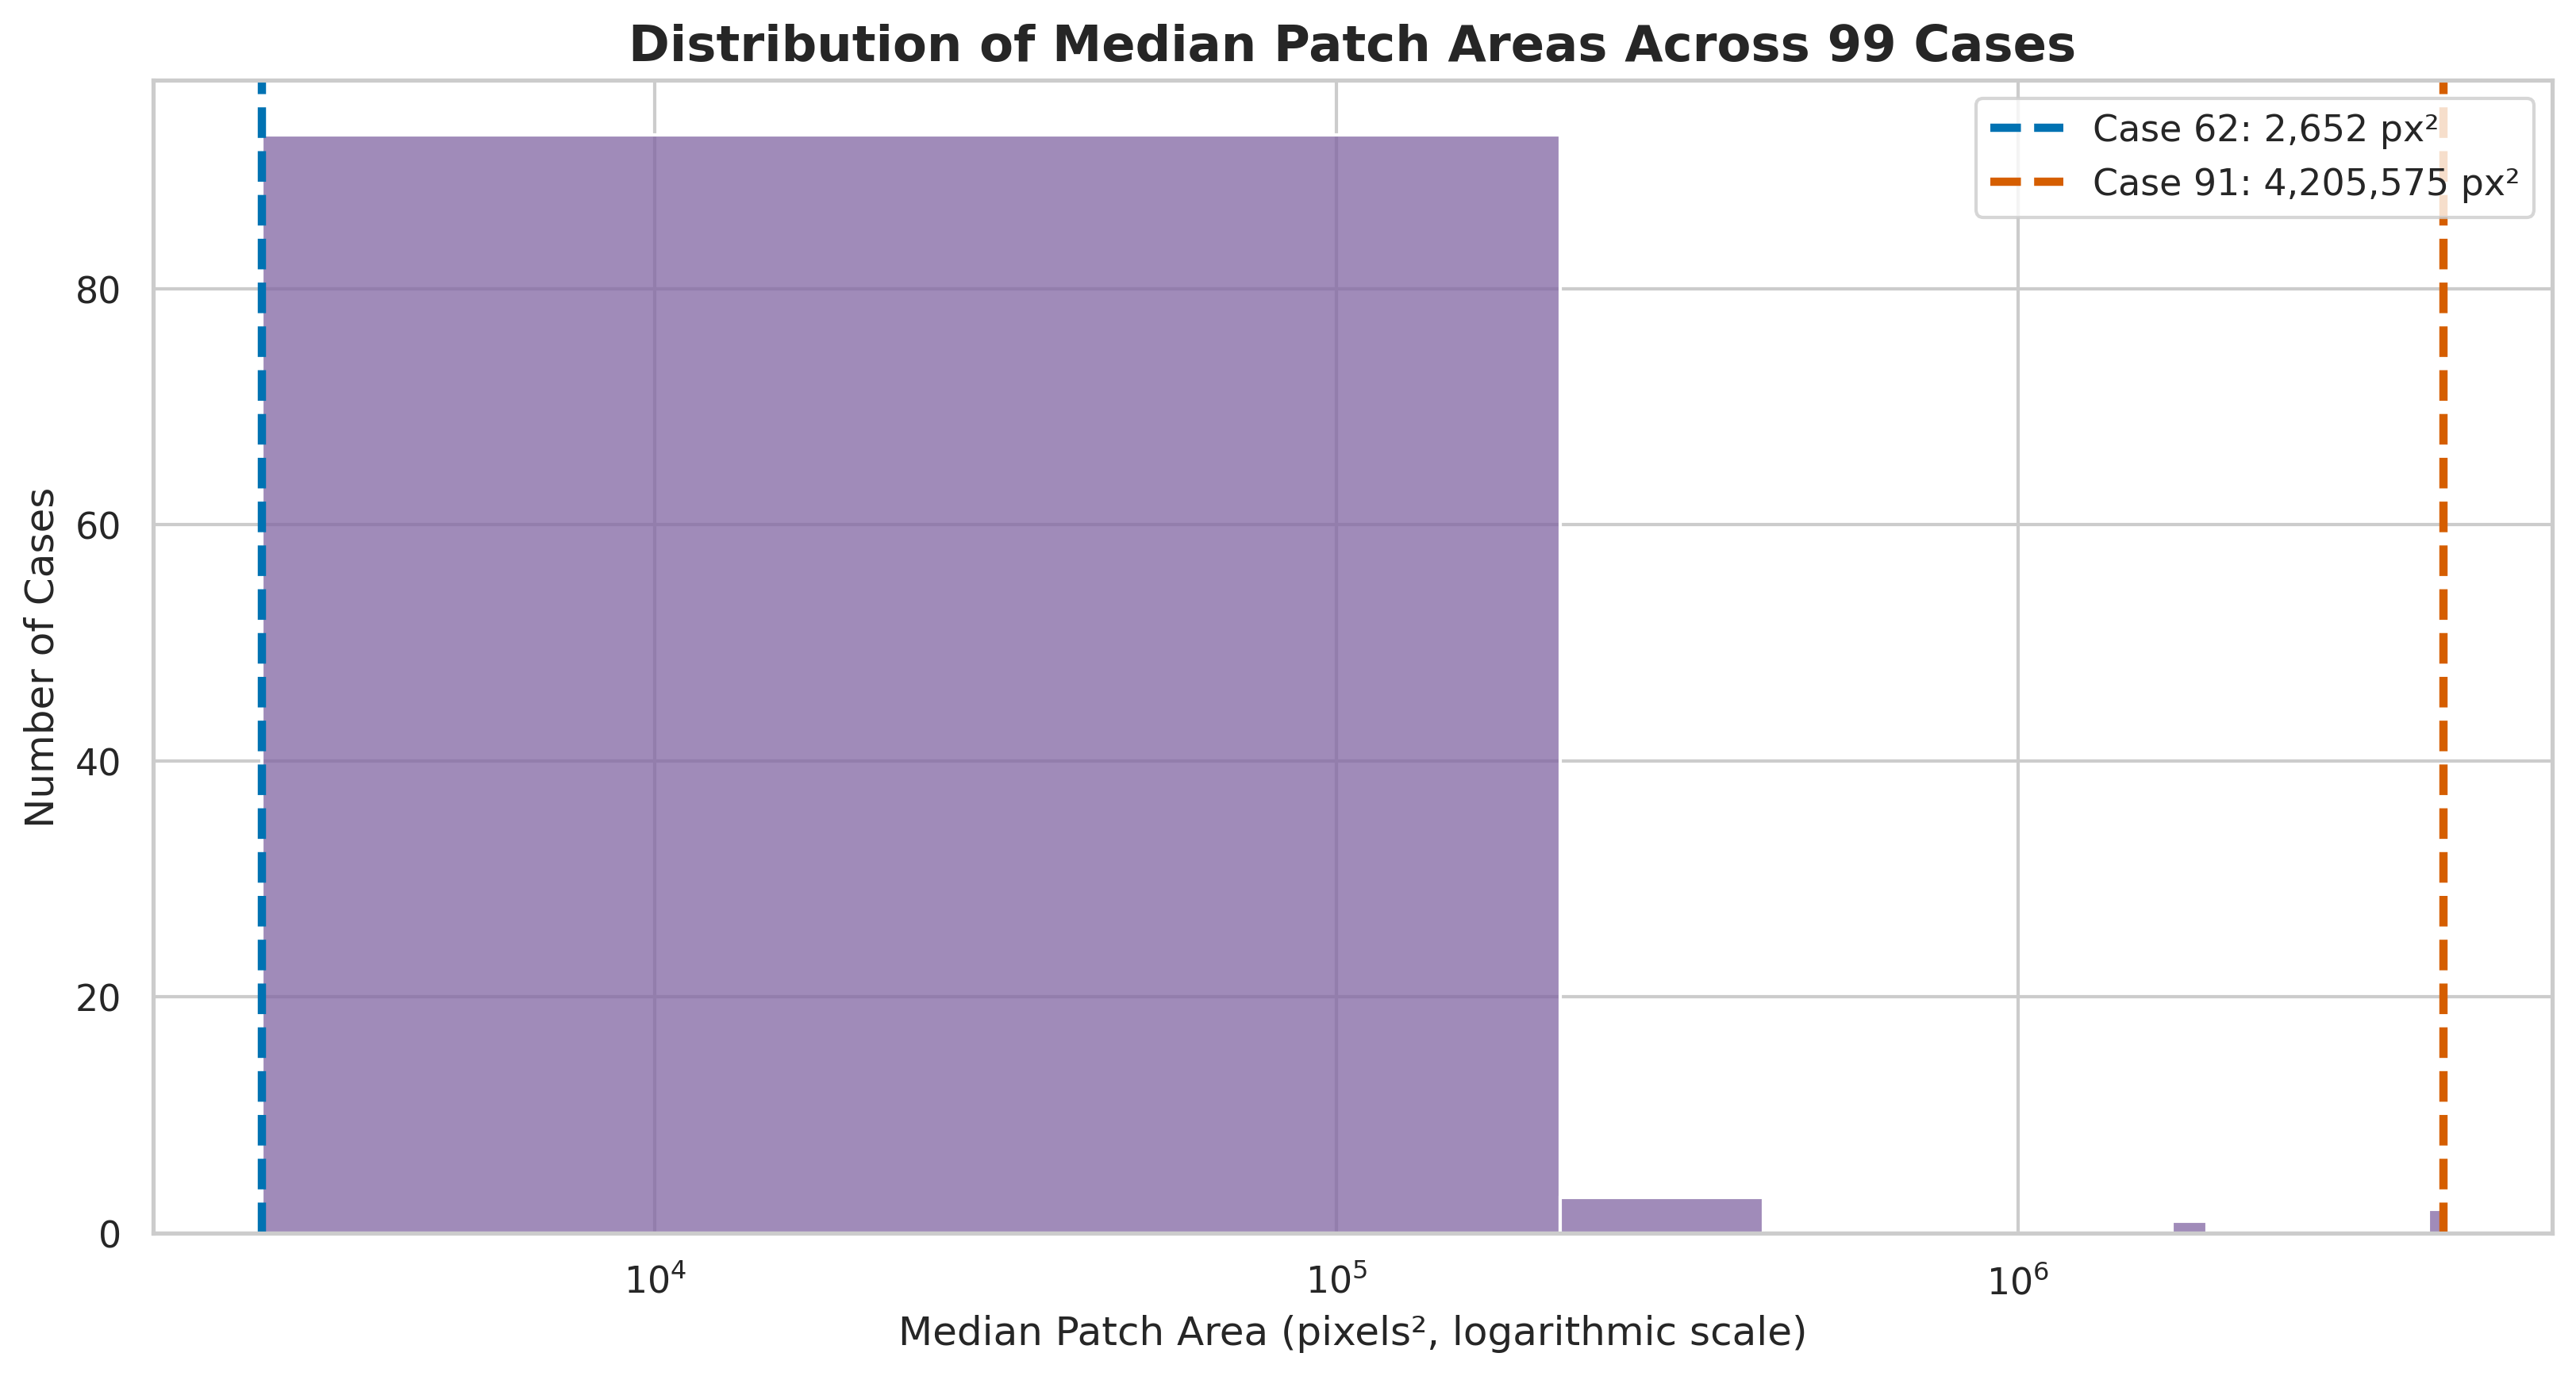

In [4]:
# VISUALIZATION 1: MEDIAN PATCH SIZE ACROSS CASES

import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("case_patch_features.csv")

assert len(df) == 99
assert (df["median_patch_area"] > 0).all()

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 6))

# Distribution across all 99 cases.
sns.histplot(
    data=df,
    x="median_patch_area",
    bins=20,
    color="#8064A2",
    edgecolor="white",
    ax=ax
)

# Highlight two especially unusual cases.
for case_id, color in [(62, "#0072B2"), (91, "#D55E00")]:

    value = df.loc[
        df["case_id"] == case_id,
        "median_patch_area"
    ].iloc[0]

    ax.axvline(
        value,
        color=color,
        linestyle="--",
        linewidth=2.5,
        label=f"Case {case_id}: {value:,.0f} px²"
    )

ax.set_xscale("log")

ax.set_title(
    "Distribution of Median Patch Areas Across 99 Cases",
    fontsize=15,
    weight="bold"
)

ax.set_xlabel("Median Patch Area (pixels², logarithmic scale)")
ax.set_ylabel("Number of Cases")

ax.legend()
plt.tight_layout()

output_path = "median_patch_area_distribution.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print("VISUALIZATION CREATED")
print("=" * 55)
print("Output:", output_path)
print("Cases represented:", len(df))
print("Case 62 median area:",
      df.loc[df["case_id"] == 62, "median_patch_area"].iloc[0])
print("Case 91 median area:",
      df.loc[df["case_id"] == 91, "median_patch_area"].iloc[0])


## Visualization 2: Comparing Extreme Patch-Size Distributions

Cases 62 and 91 were identified as statistical outliers in the case-level feature analysis.

- **Case 62:** Contains 1,604 patches, with a median area of 2,652 pixels².
- **Case 91:** Contains 530 patches, with a median area of 4,205,575 pixels².

The histograms compare the distributions of individual patch areas.

Both plots use the same logarithmic horizontal scale and display percentages, allowing comparison despite different patch counts.

These plots describe differences in patch dimensions. They do not establish whether either case is difficult for the classification model.


COMPARISON VISUALIZATION CREATED
Case 62 patches: 1604
Case 91 patches: 530


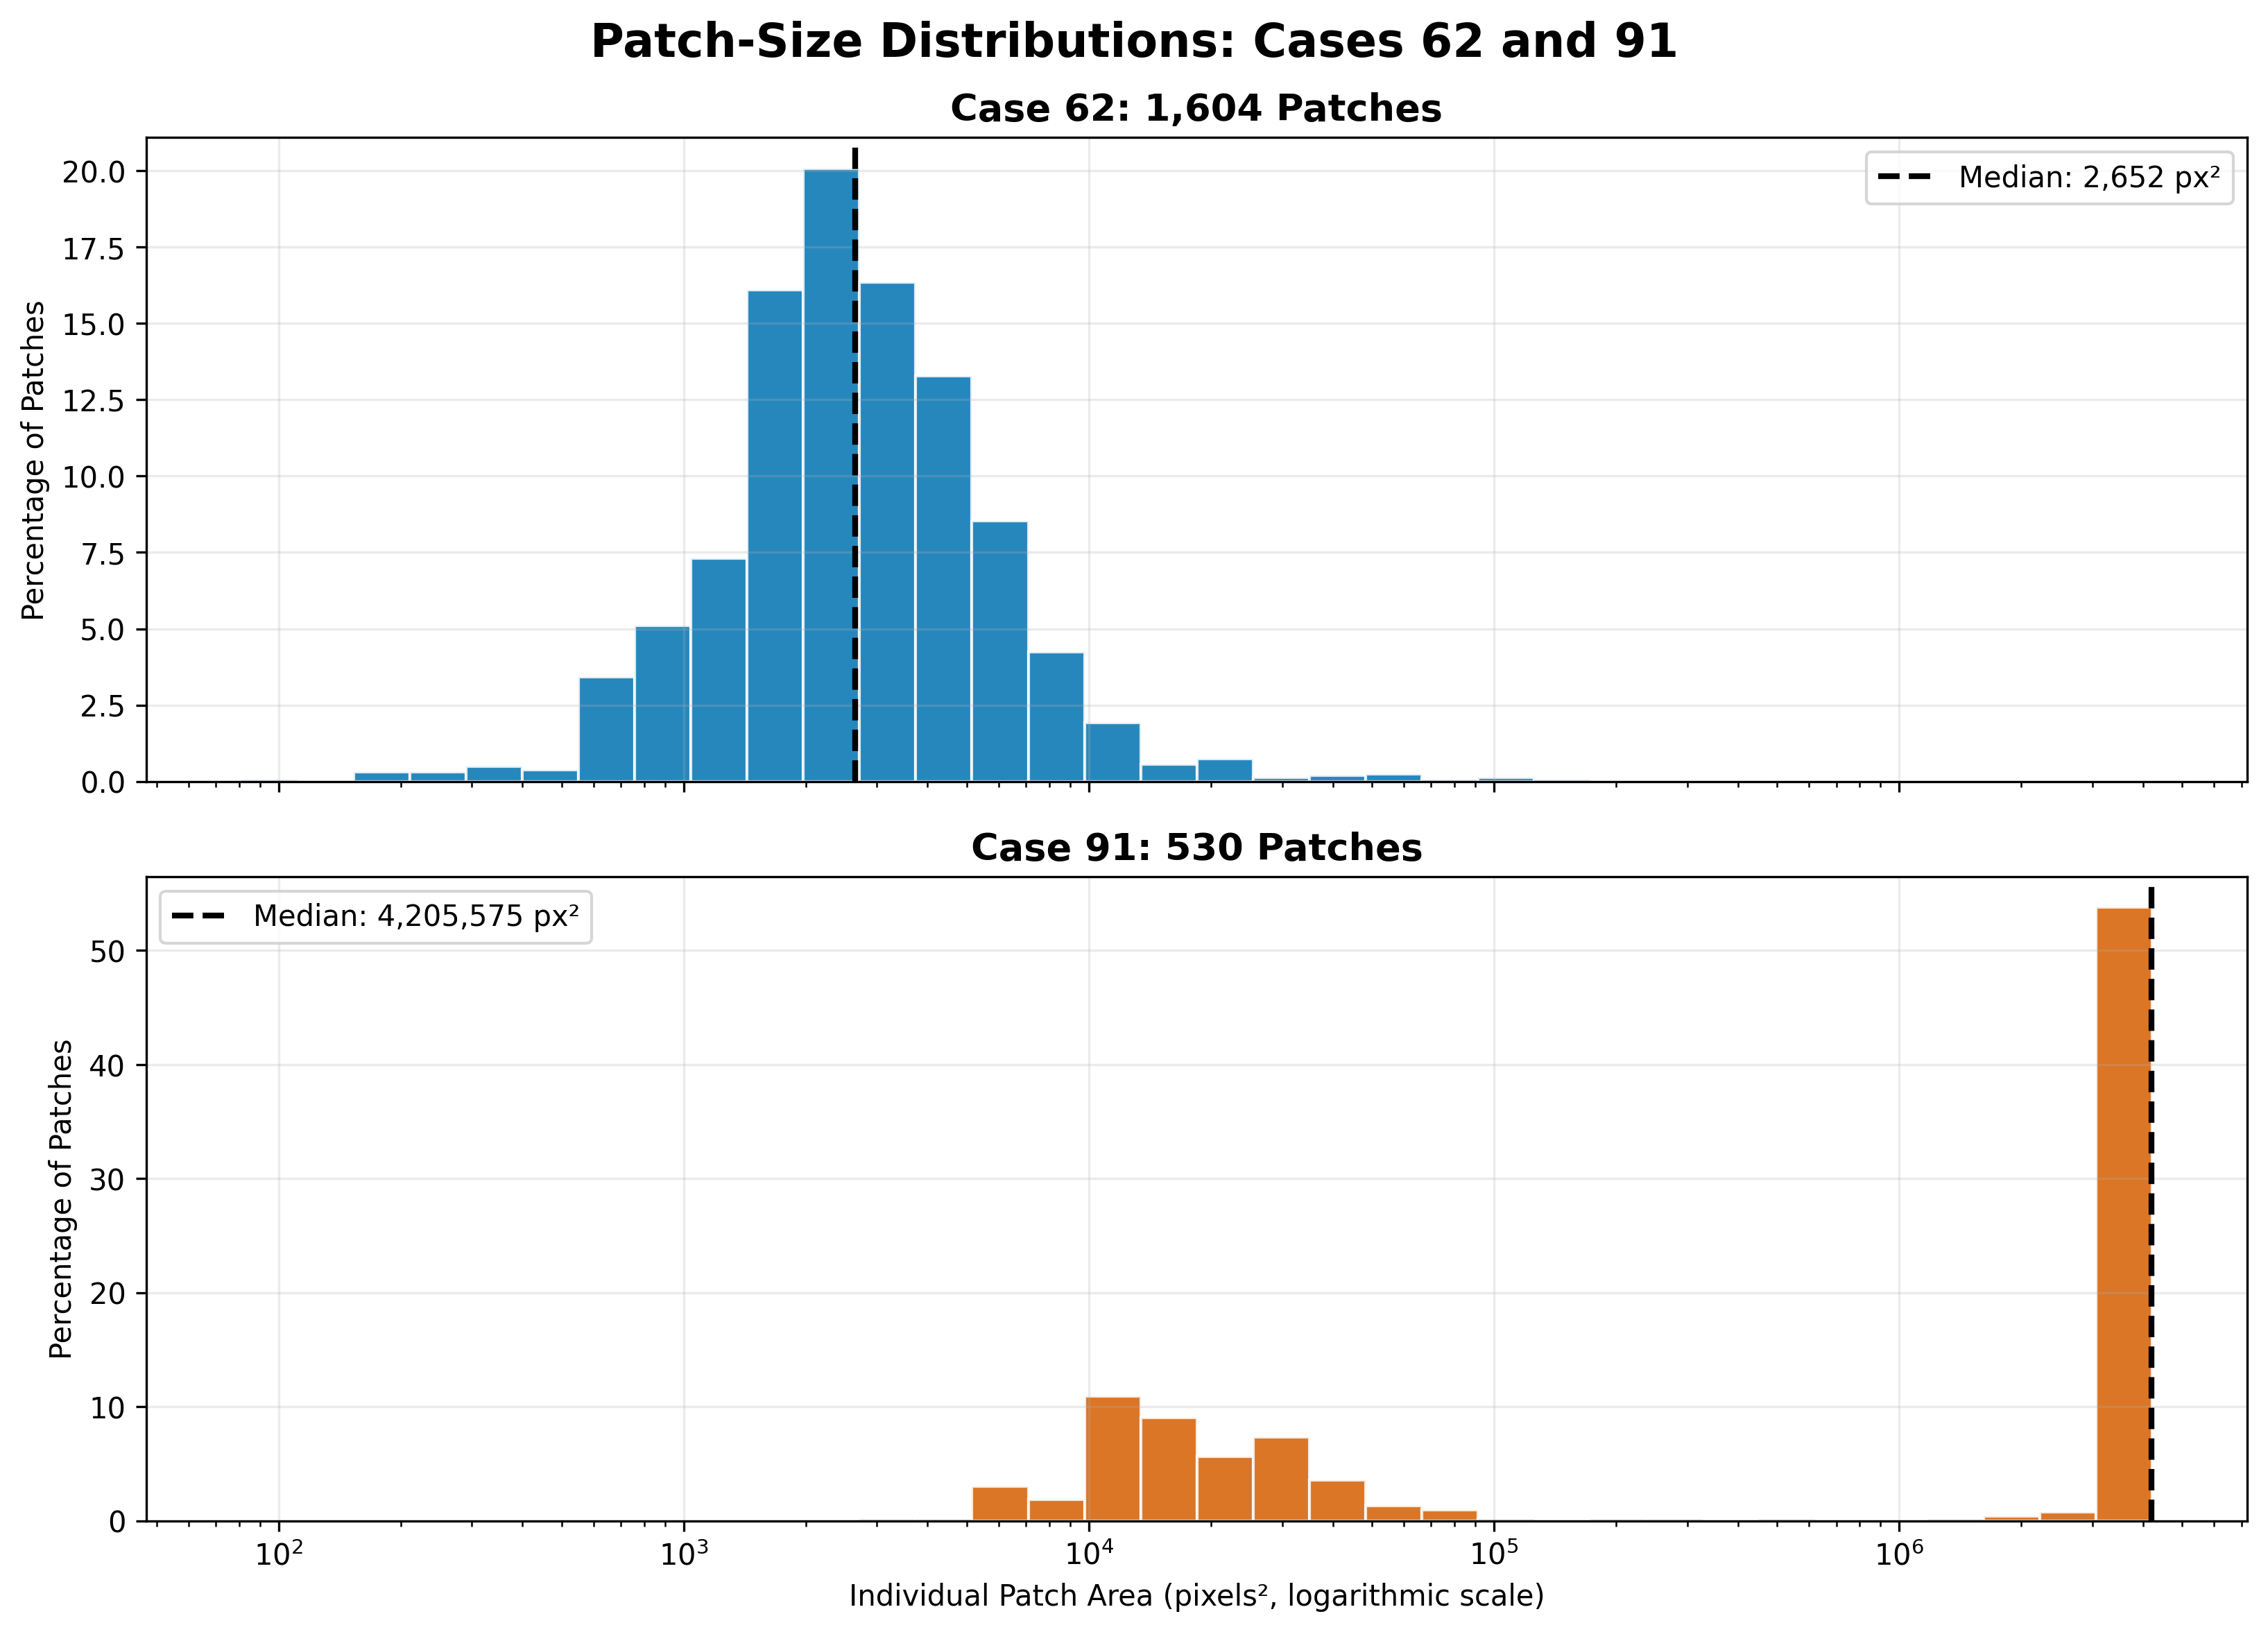

In [5]:
# VISUALIZATION 2: CASE 62 VS. CASE 91

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("patch_features_corrected.csv")

case_ids = [62, 91]
colors = ["#0072B2", "#D55E00"]

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True
)

# Use identical logarithmic bins for both cases.
all_areas = df.loc[
    df["case_id"].isin(case_ids),
    "area_px2"
]

assert (all_areas > 0).all()

bins = np.logspace(
    np.log10(all_areas.min()),
    np.log10(all_areas.max()),
    35
)

for ax, case_id, color in zip(axes, case_ids, colors):

    case = df[df["case_id"] == case_id]

    # Express each bin as a percentage of the case's patches.
    weights = np.full(
        len(case),
        100 / len(case)
    )

    ax.hist(
        case["area_px2"],
        bins=bins,
        weights=weights,
        color=color,
        edgecolor="white",
        alpha=0.85
    )

    median = case["area_px2"].median()

    ax.axvline(
        median,
        color="black",
        linestyle="--",
        linewidth=2,
        label=f"Median: {median:,.0f} px²"
    )

    ax.set_xscale("log")

    ax.set_title(
        f"Case {case_id}: {len(case):,} Patches",
        fontsize=13,
        weight="bold"
    )

    ax.set_ylabel("Percentage of Patches")
    ax.legend()
    ax.grid(alpha=0.25)

axes[-1].set_xlabel(
    "Individual Patch Area (pixels², logarithmic scale)"
)

fig.suptitle(
    "Patch-Size Distributions: Cases 62 and 91",
    fontsize=16,
    weight="bold"
)

plt.tight_layout()

output_path = "case_62_vs_91_patch_sizes.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.close(fig)

print("COMPARISON VISUALIZATION CREATED")
print("=" * 55)
print("Output:", output_path)
print("Case 62 patches:", len(df[df["case_id"] == 62]))
print("Case 91 patches:", len(df[df["case_id"] == 91]))


## Final Findings — Data Engineer Choice 2

### 1. Dataset Summary

We analyzed **85,413 PNG patches across 99 eligible cases**.

For each patch, we extracted its width, height, and area in pixels. We also standardized stain classifications and summarized patch characteristics at the case level.

The case-level features include:

- Total patches and patches per slice
- Median patch area
- Interquartile range (IQR) of patch area
- Proportion of small patches
- Proportion of H&E, Melan-A, and SOX10 patches

### 2. Unusual Cases

Using Tukey's 1.5 × IQR rule, we identified **31 statistical outlier flags**.

Additional checks identified:

- 4 missing-stain flags
- 4 filename-review flags

In total, **23 distinct cases received 39 flags**. A case could receive multiple flags.

These flags identify unusual data characteristics; they do not establish that the model misclassifies the case.

### 3. Key Examples

**Case 16 — Missing stains**

All 177 available patches are H&E. No Melan-A or SOX10 patches were found.

This means the case has less stain variety available for classification.

**Case 62 — Extremely small patches**

Case 62 contains 1,604 patches with a median area of 2,652 pixels².

Approximately 98.3% of its patches meet our small-patch definition (both width and height below 128 pixels).

The small patch sizes occur across all three stains.

**Case 91 — Extremely large and variable patches**

Case 91 contains 530 patches with a median area of 4,205,575 pixels².

Approximately 53.6% of patches are wider than 1,800 pixels, while 44.5% are 512 pixels wide or smaller.

This indicates substantial variation in patch dimensions within the same case.

**Case 46 — Unusual benign case**

Case 46 is benign but has an unusually large median patch area of 159,201 pixels² and a patch-area IQR of 431,776 pixels².

Unusual patch characteristics are therefore not limited to high-grade cases.

### 4. Potential Implications

These findings suggest several characteristics worth investigating:

- Missing stains may reduce the information available to the model.
- Very small patches may capture less surrounding tissue context.
- Very large or inconsistent patch dimensions may reflect differences in image acquisition or patch generation.

These are possible explanations, **not demonstrated causes of classification difficulty**.

### 5. Limitations and Next Steps

- The analysis covers 99 cases with available PNG patches and eligible labels.
- Two eligible labeled cases (112 and 113) have no PNG patches in the analyzed directory.
- Filenames containing `h&e-labels` were flagged for review; their visual contents were not independently verified.
- Missing-stain flags describe absent PNG patches, not necessarily absent original slide images.
- Model predictions and embedding availability were not analyzed here.
- A useful follow-up would compare the flagged cases with actual classification errors to test whether unusual patch features are associated with model difficulty.

### 6. Deliverables

1. `patch_features_corrected.csv` — patch-level measurements
2. `case_patch_features.csv` — one row per eligible case
3. `unusual_cases.csv` — case-level flags and thresholds
4. `median_patch_area_distribution.png` — overall patch-size distribution
5. `case_62_vs_91_patch_sizes.png` — comparison of two extreme cases

All outputs were generated in the personal project directory.
